# DK1 forecast-error report appendix

This notebook regenerates the report tables, rule-transfer figure, and Ridge
moving-block intervals. In 2024, autumn evenings had elevated large-error
rates across five models (lift 1.77–2.54). The cluster-0 afternoon rule
showed little enrichment.

## Setup and inputs

Unzip the appendix, install the pinned Python dependencies, and run all cells
from the appendix root or the notebook directory. See the bundled README for
commands and model provenance.

The five forecast files preserve the exact hourly outputs used in the report.
The notebook validates their UTC timestamps, Copenhagen dates and clock hours,
and actual prices against the bundled snapshot. It refits K-means on the
pre-2023 features and checks all 731 labels against the report labels.
Table II uses the annual scores from the model-sensitivity runs.

2023 is the rule-calibration year and 2024 is a chronological evaluation
within historical development. Historical release and revision times are
partly audited. Intervals condition on the fixed forecasts, rules, and threshold.

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

bundle = root / "team" / "report_inputs"
if not bundle.is_dir():
    raise FileNotFoundError("Run this notebook from the extracted report appendix.")
sys.path.insert(0, str(root / "scripts"))
from postprocess_team import run

inputs = {
    model: bundle / f"{model}.csv.gz"
    for model in ("ridge", "lasso", "random_forest", "gradient_boosting", "mlp")
}
regimes = bundle / "regimes.csv"
output = root / "results" / "appendix"

subprocess.run(
    [
        sys.executable, str(root / "team/b-random-forest/cluster_regimes.py"),
        "--features", str(root / "team/data/features.csv.gz"),
        "--output-dir", str(output / "clusters"),
    ],
    check=True,
)
pd.testing.assert_frame_equal(
    pd.read_csv(regimes), pd.read_csv(output / "clusters/regimes.csv")
)
annual = run(inputs, regimes, output)
names = {
    "ridge": "Ridge",
    "lasso": "Lasso",
    "random_forest": "Random Forest",
    "gradient_boosting": "Gradient Boosting",
    "mlp": "MLP",
    "equal_blend": "Equal weights",
    "global_blend": "Pooled weights",
    "regime_blend": "Regime weights",
}

## Forecast accuracy and tuning

In [2]:
# Table I and the negative-price subgroup discussed in the report.
metrics = annual.loc[annual.model.isin(inputs)].replace({"model": names})
metrics = metrics.assign(hit_pct=100 * metrics.rate_5pct)
metrics.set_index(["year", "model"])[
    ["hours", "mae", "rmse", "eligible", "hit_pct", "negative_hours", "negative_mae"]
].round(2)

hours    mae   rmse  eligible  hit_pct  \
year model                                                       
2023 Ridge               8760  18.78  26.65      7738    20.35   
     Lasso               8760  17.91  26.14      7738    21.85   
     Random Forest       8760  21.00  30.50      7738    20.65   
     Gradient Boosting   8760  18.39  26.87      7738    22.87   
     MLP                 8760  20.22  27.79      7738    16.81   
2024 Ridge               8784  18.34  29.52      7620    17.80   
     Lasso               8784  17.84  29.35      7620    18.75   
     Random Forest       8784  18.98  31.56      7620    18.31   
     Gradient Boosting   8784  16.58  27.47      7620    19.09   
     MLP                 8784  19.19  30.07      7620    16.08   

                        negative_hours  negative_mae  
year model                                            
2023 Ridge                         281         31.56  
     Lasso                         281         30.94  
     Random Forest                 281         48.23  
     Gradient Boosting             281         35.30  
     MLP                           281         33.74  
2024 Ridge                         375         19.43  
     Lasso                         375         19.79  
     Random Forest                 375         29.52  
     Gradient Boosting             375         20.69  
     MLP                           375         24.38

In [3]:
# Table II. The bundled tables archive the sensitivity runs.
lasso_starter = pd.read_csv(bundle / "lasso_starter_metrics.csv").set_index("year")
forest = pd.read_csv(bundle / "forest_leaf_sensitivity.csv").pivot(
    index="year", columns="model", values="mae"
)
mlp_starter = pd.read_csv(bundle / "mlp_paired_mae.csv").query("model == 'mlp-starter'")
mlp_starter = mlp_starter.set_index("year")
annual_mae = annual.pivot(index="year", columns="model", values="mae")
pd.DataFrame({
    "Lasso tuned − starter": annual_mae.lasso - lasso_starter.mae,
    "Forest leaf 2 − leaf 5": forest["RF leaf=2 (rule-selected)"] - forest["RF leaf=5 (chosen)"],
    "MLP tuned − starter": annual_mae.mlp - mlp_starter.mae_candidate,
}).T.round(2)

year,2023,2024
Lasso tuned − starter,-2.74,-1.30
Forest leaf 2 − leaf 5,-0.14,-0.07
MLP tuned − starter,-2.24,-1.18


In [4]:
# Boosting selection and the 2024 eligible-hit sensitivity.
boosting = pd.read_csv(bundle / "boosting_variants.csv").query("run != 'ridge'")
boosting.assign(hit_pct=100 * boosting.rate_5pct).set_index(["year", "run"])[
    ["mae", "rmse", "hit_pct"]
].round(2)

,,mae,rmse,hit_pct
year,run,,,
2023,gradient_boosting_baseline,18.39,26.87,22.87
2024,gradient_boosting_baseline,16.58,27.47,19.09
2023,gradient_boosting_smaller_leaves,18.95,27.43,21.71
2024,gradient_boosting_smaller_leaves,17.72,28.81,17.61
2023,gradient_boosting_strong_l2,18.66,27.24,22.41
2024,gradient_boosting_strong_l2,16.65,27.60,18.70
2023,gradient_boosting_absolute_loss,19.11,27.86,21.87
2024,gradient_boosting_absolute_loss,17.32,28.97,20.70


## Market regimes

In [5]:
pd.read_csv(output / "clusters/regime_centers.csv", index_col="cluster").round(2)

,train_days,2023_days,2024_days,prior_price_mean,prior_price_sd,prior_morning_evening_spread,forecast_temperature_mean,forecast_wind_speed_mean,forecast_cloud_cover_mean
cluster,,,,,,,,,
0,487,129,131,65.91,18.75,-5.58,7.63,24.20,78.90
1,302,80,60,63.56,13.61,1.90,5.98,13.96,33.88
2,477,145,157,59.99,12.70,6.02,15.19,13.67,61.97
3,188,11,18,293.47,75.04,60.62,11.67,13.98,58.30


## Apriori rules and their transfer

The highest-lift calendar and cluster-containing antecedents are selected on
2023 Ridge errors and applied unchanged. We compare each model's frozen
2023 90th-percentile threshold with the common Ridge threshold of
40.54 EUR/MWh.

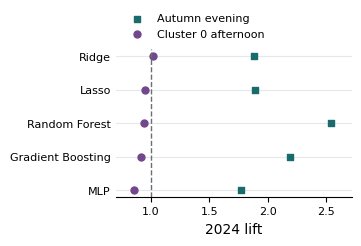

In [6]:
transfer = pd.read_csv(output / "rule_transfer.csv")
rules = transfer.loc[
    transfer.year.eq(2024)
    & transfer.definition.eq("model_2023_p90")
    & transfer.model.isin(inputs)
].pivot(index="model", columns="rule", values="lift").reindex(inputs)
rules = rules.rename(index=names, columns={
    "cluster=0 & time_of_day=afternoon": "Cluster 0 afternoon",
    "season=autumn & time_of_day=evening": "Autumn evening",
})

fig, ax = plt.subplots(figsize=(3.5, 2.35), layout="constrained")
ax.set_axisbelow(True)
ax.grid(axis="y", color="#e5e9eb")
for rule, color, marker in zip(["Autumn evening", "Cluster 0 afternoon"], ["#1A6B6C", "#73478C"], ["s", "o"]):
    ax.scatter(rules[rule], rules.index, label=rule, color=color, marker=marker, s=25)
ax.axvline(1, color="#687075", linewidth=1, linestyle="--")
ax.set(xlabel="2024 lift", xlim=(0.7, 2.72))
ax.invert_yaxis()
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.tick_params(labelsize=8)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), frameon=False, fontsize=8)
fig.savefig(output / "rule_transfer.pdf")
plt.show()

In [7]:
ridge_rules = pd.read_csv(output / "apriori_ridge.csv", index_col="antecedent")
ridge_rules[["development_lift", "evaluation_lift"]].round(2)

,development_lift,evaluation_lift
antecedent,,
season=autumn & time_of_day=evening,2.18,1.88
cluster=0 & time_of_day=afternoon,1.61,1.02


In [8]:
# Table III. All rows use the frozen model-specific thresholds.
from postprocess_team import aligned_inputs

scored = aligned_inputs(inputs, regimes)
in_2024 = scored.year.eq(2024)
is_afternoon = scored.time_of_day.eq("afternoon")
is_evening = scored.time_of_day.eq("evening")
conditions = {
    "All hours": in_2024,
    "Autumn evenings": in_2024 & scored.season.eq("autumn") & is_evening,
    "Cluster-0 afternoons": in_2024 & scored.cluster.eq(0) & is_afternoon,
    "Other afternoons": in_2024 & scored.cluster.ne(0) & is_afternoon,
}
table = pd.DataFrame({"Hours": {name: int(mask.sum()) for name, mask in conditions.items()}})
for model in ("ridge", "gradient_boosting"):
    error = scored[model].sub(scored.actual).abs()
    is_event = error.gt(error.loc[scored.year.eq(2023)].quantile(0.90))
    table[names[model]] = {name: int(is_event.loc[mask].sum()) for name, mask in conditions.items()}
table

,Hours,Ridge,Gradient Boosting
All hours,8784,787,551
Autumn evenings,546,92,75
Cluster-0 afternoons,786,72,45
Other afternoons,1410,159,140


## Ridge rate differences

For the autumn rule, the comparison holds the six-hour evening band fixed.
For the cluster rule, it holds the afternoon band fixed. Both intervals use
5,000 paired draws of contiguous seven-day blocks.

In [9]:
pd.read_csv(output / "ridge_rule_contrasts.csv", index_col="contrast").round(4)

,matched_events,matched_hours,control_events,control_hours,matched_rate,control_rate,difference_pp,ci_low_pp,ci_high_pp,valid_draws
contrast,,,,,,,,,,
cluster_0_vs_other_afternoons,72,786,159,1410,0.0916,0.1128,-2.1163,-8.3273,3.4975,5000
autumn_vs_other_evenings,92,546,161,1650,0.1685,0.0976,7.0922,1.0548,13.6287,5000


## Additional exploratory checks

In [10]:
adjusted = pd.read_csv(output / "cluster_rule_adjusted.csv").set_index("model")
adjusted.loc[list(inputs), ["target_hours", "other_hours", "difference_pp"]].rename(
    index=names, columns={"difference_pp": "Season-adjusted rate difference (pp)"}
).round(2)

,target_hours,other_hours,Season-adjusted rate difference (pp)
model,,,
Ridge,786,1410,-4.73
Lasso,786,1410,-5.28
Random Forest,786,1410,-4.30
Gradient Boosting,786,1410,-5.91
MLP,786,1410,-6.23


Autumn evenings had elevated lift under the common Ridge threshold as well.
The season-adjusted afternoon comparison showed no elevated rate for
cluster 0. These are historical results. A prospective evaluation would
measure whether the autumn-evening flag continues to identify large errors.

### Forecast combination

The regime-specific inverse MAE weights borrow the equivalent of 720 hours
from the pooled estimate. All weights are fitted in 2023. The 2024 ±5% hit rate
uses 7,620 hours with absolute actual price of at least 20 EUR/MWh.

In [11]:
scores = annual.loc[annual.year.eq(2024)].set_index("model").rename(index=names)
scores.assign(hit_pct=100 * scores.rate_5pct)[
    ["mae", "rmse", "hits_5pct", "hit_pct", "negative_hours", "negative_mae"]
].sort_values("mae").round(2)

,mae,rmse,hits_5pct,hit_pct,negative_hours,negative_mae
model,,,,,,
Gradient Boosting,16.58,27.47,1455,19.09,375,20.69
Regime weights,16.64,27.91,1513,19.86,375,21.53
Pooled weights,16.64,27.92,1521,19.96,375,21.52
Equal weights,16.69,27.98,1518,19.92,375,21.76
Lasso,17.84,29.35,1429,18.75,375,19.79
Ridge,18.34,29.52,1356,17.80,375,19.43
Random Forest,18.98,31.56,1395,18.31,375,29.52
MLP,19.19,30.07,1225,16.08,375,24.38


In [12]:
paired = pd.read_csv(output / "paired_mae.csv")
comparison = paired.loc[
    paired.model.eq("regime_blend") & paired.baseline.eq("global_blend")
].set_index("block_days")
comparison[["delta_mae", "ci_low", "ci_high"]].round(4)

,delta_mae,ci_low,ci_high
block_days,,,
3,-0.008,-0.0176,0.0004
7,-0.008,-0.0176,0.0008
14,-0.008,-0.0176,0.0010


Each moving-block draw resamples the same delivery days for both forecasts,
retains all hours including DST transitions, and averages the paired differences
over the hours drawn. All three block lengths give an interval spanning zero.
Gradient Boosting had the lowest observed 2024 MAE, and pooled weighting had
the highest eligible hit rate.